# 05 — Step 4: quality tiers

Step 4 decides which movies are not worth recommending and how much weight the rest get. Each sub-question below is its own piece of research (question, why it matters, method, results, interpretation, limitations, decision). The write-up is in `docs/findings/tiers.md`.

| | Sub-question | Status |
|---|---|---|
| Q4.1 | How many ratings until a movie's mean is trustworthy? | decided: reliability 0.8 (28 ratings), flags only |
| Q4.2 | Age boundaries | deferred (future work, see PROJECT.md §14) |
| Q4.3 | Trusted rating measure | decided: shrunk mean, k = 7.3 |
| Q4.4 | Rating floor | decided: keep 04's μ − 1σ per-genre rule; "too high" judged on the shrunk score |
| Q4.5 | New-movie range | deferred: no post-2019 data |
| Q4.6 | Sensitivity | done |
| Q4.7 | Validation on later ratings | done: rule and tiers validated |

**Decisions already made**
- Thresholds are genre-specific (a movie with several genres is counted in each of them and gets the most lenient value).
- No age buckets for now; the existing time test stays.
- New movies use content features plus CF, with the CF weight growing as ratings arrive.

Reusable code lives in `src/viberec/credibility.py` (with tests in `tests/`). This notebook only calls it.

## Config and load

Q4.1 runs on the 50,046 rated movies in `movies_full.parquet` (after the titleType filter), because those are the movies the tiers apply to.

The numbers below are computational settings, not thresholds on the results. `LEVELS` are just the reliability levels reported in the tables; 

In [1]:
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve()))   # lets the notebook import src/
from src.viberec import credibility as cr

PROCESSED_DIR = Path("..") / "data" / "processed"
ARTIFACTS_DIR = Path("..") / "artifacts"
FIGURES_DIR = Path("..") / "docs" / "findings" / "figures"
RATINGS_CSV = Path("..") / "data" / "raw" / "movielens" / "ml-25m" / "ratings.csv"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
VERSION = "v1"
N_STRATA = 14                 # rating-count groups used to report results (display only)
N_REPEATS = 80                # random half-splits per movie (see the convergence check)
N_BOOT = 1000                 # bootstrap resamples per movie
N_BOOT_MOVIES = 4000          # resamples of the movie set for the genre comparison
REPEATS_IN_BOOT = 40          # half-split repeats used inside each movie resample
MIN_MOVIES_PER_STRATUM = 50   # a stratum with fewer movies is not used for a curve
LEVELS = [0.5, 0.7, 0.8, 0.9] # reliability levels reported in the tables

# chart colours: first three categorical slots of the reference palette, plus neutrals
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e3e2de"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"


def write_metadata(path, **info):
    """Small JSON next to a saved output: what produced it, when, with which settings."""
    meta = {"created_at": datetime.now(timezone.utc).isoformat(),
            "produced_by": "notebooks/05_quality_tiers.ipynb", **info}
    path.with_name(path.stem + ".metadata.json").write_text(json.dumps(meta, indent=2, default=str))


def style_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)


movies = pd.read_parquet(PROCESSED_DIR / "movies_full.parquet")
movies["genres"] = movies["genres"].str.replace(",", "|", regex=False)   # IMDb-filled genres use ","
rated = movies[movies["rating_count"].notna()].copy()
print(f"{len(rated):,} rated movies (population for Q4.1)")

50,046 rated movies (population for Q4.1)


## 1. Rating histogram per movie

Everything in Q4.1 needs each movie's ratings, but not the 25M raw rows. A movie's ratings take only 10 values (0.5 to 5.0), so one row of 10 counts per movie holds all the information. Resampling or splitting that row is equivalent to resampling or splitting the raw ratings, and it is thousands of times cheaper.

The table is built once from `ratings.csv` and saved to `data/processed/`; later runs load it. It is checked against the `rating_count` and `mean_rating` already in `movies_full.parquet`.

In [2]:
HIST_PATH = PROCESSED_DIR / f"movie_rating_histogram_{VERSION}.parquet"

if HIST_PATH.exists():
    print(f"{HIST_PATH} already exists, loading instead of recomputing.")
    hist = pd.read_parquet(HIST_PATH)
else:
    start = time.time()
    hist = cr.build_rating_histogram(RATINGS_CSV, rated["movieId"])
    hist.to_parquet(HIST_PATH, index=False)
    write_metadata(HIST_PATH, source="data/raw/movielens/ml-25m/ratings.csv",
                   population="rated movies in movies_full.parquet", movies=len(hist),
                   total_ratings=int(hist[cr.LEVEL_COLS].to_numpy().sum()),
                   runtime_seconds=round(time.time() - start, 1))
    print(f"saved {len(hist):,} rows to {HIST_PATH}")

counts = hist[cr.LEVEL_COLS].to_numpy()
n, mean, var = cr.hist_stats(counts)
catalog = rated.set_index("movieId").loc[hist["movieId"]]   # same movie order as the histogram

# the histogram must reproduce the counts and means already in movies_full.parquet
assert (n == catalog["rating_count"].to_numpy()).all()
assert np.allclose(mean, catalog["mean_rating"].to_numpy())
print(f"{len(n):,} movies, {n.sum():,} ratings; counts and means match movies_full.parquet")
print(f"movies with 1 rating: {(n == 1).mean():.1%}, with 2 or fewer: {(n <= 2).mean():.1%}")

../data/processed/movie_rating_histogram_v1.parquet already exists, loading instead of recomputing.
50,046 movies, 24,744,432 ratings; counts and means match movies_full.parquet
movies with 1 rating: 16.4%, with 2 or fewer: 29.0%


## 2. Check the assumptions before choosing a method

A standard error such as σ/√n assumes the mean of n ratings is roughly normal and that σ is the same for every movie. Neither is given, so check the data:
- the shape of individual ratings (are they symmetric?)
- whether the within-movie variance depends on how many ratings a movie has
- whether it depends on the movie's mean (ratings are capped at 5.0 and 0.5, so it might)

Within-movie variance can only be measured for movies with at least 2 ratings.

share of ratings by value: {np.float64(0.5): np.float64(0.015), np.float64(1.0): np.float64(0.031), np.float64(1.5): np.float64(0.016), np.float64(2.0): np.float64(0.066), np.float64(2.5): np.float64(0.051), np.float64(3.0): np.float64(0.196), np.float64(3.5): np.float64(0.127), np.float64(4.0): np.float64(0.266), np.float64(4.5): np.float64(0.088), np.float64(5.0): np.float64(0.144)}
pooled within-movie variance, all movies with n >= 2: 0.916
skewness of a single movie's ratings (movies with 50+ ratings): median -0.59, 5th to 95th percentile -1.35 to 0.20

                 movies  pooled_var
bin                               
[2.0, 3.0)      6293.0       1.069
[3.0, 4.0)      4029.0       1.142
[4.0, 5.0)      2779.0       1.158
[5.0, 7.0)      3561.0       1.181
[7.0, 10.0)     3225.0       1.142
[10.0, 20.0)    4933.0       1.073
[20.0, 50.0)    4490.0       1.075
[50.0, 100.0)   2558.0       1.021
[100.0, 500.0)  4665.0       0.970
[500.0, inf)    5314.0       0.911

              

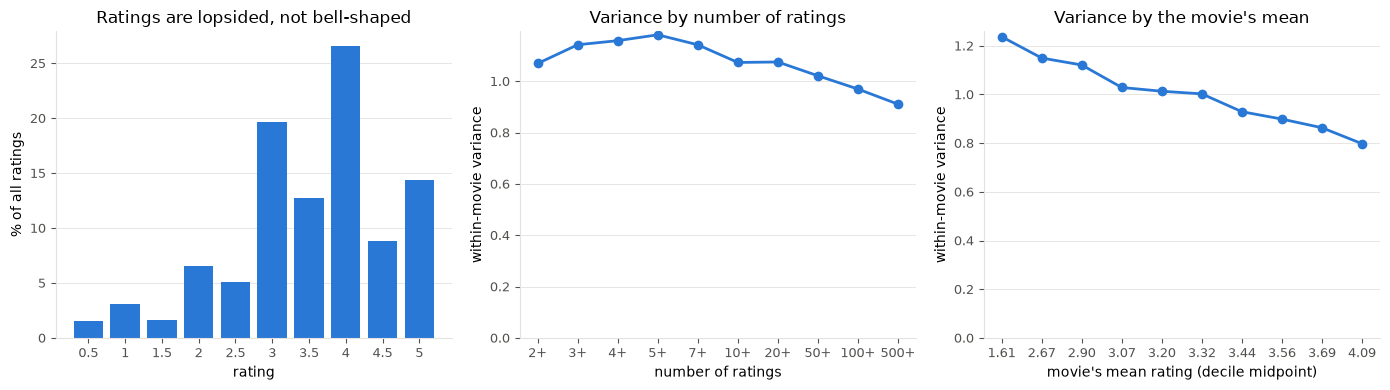

In [3]:
pooled = lambda n_, v_: np.sum((n_ - 1) * v_) / np.sum(n_ - 1)   # variance pooled over movies
has_var = n >= 2

# overall share of each rating value
share = counts.sum(axis=0) / counts.sum()

# pooled within-movie variance by number of ratings (n >= 2)
n_bins = pd.cut(n[has_var], [2, 3, 4, 5, 7, 10, 20, 50, 100, 500, np.inf], right=False)
by_n = (pd.DataFrame({"n": n[has_var], "var": var[has_var], "bin": n_bins})
        .groupby("bin", observed=True).apply(lambda d: pd.Series({"movies": len(d), "pooled_var": pooled(d["n"], d["var"])})))

# pooled within-movie variance by the movie's mean, using movies with 10+ ratings (stable means)
big = n >= 10
mean_bins = pd.qcut(mean[big], 10)
by_mean = (pd.DataFrame({"n": n[big], "var": var[big], "bin": mean_bins})
           .groupby("bin", observed=True).apply(lambda d: pd.Series({"movies": len(d), "pooled_var": pooled(d["n"], d["var"])})))

skew = [pd.Series(np.repeat(cr.RATING_LEVELS, row)).skew() for row in counts[n >= 50]]
print("share of ratings by value:", dict(zip(cr.RATING_LEVELS, share.round(3))))
print(f"pooled within-movie variance, all movies with n >= 2: {pooled(n[has_var], var[has_var]):.3f}")
print(f"skewness of a single movie's ratings (movies with 50+ ratings): median {np.median(skew):.2f}, "
      f"5th to 95th percentile {np.percentile(skew, 5):.2f} to {np.percentile(skew, 95):.2f}")
print("\n", by_n.round(3).to_string())
print("\n", by_mean.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(cr.RATING_LEVELS, share * 100, width=0.4, color=BLUE)
axes[0].set_xticks(cr.RATING_LEVELS, [f"{r:g}" for r in cr.RATING_LEVELS], fontsize=8)
axes[0].set(xlabel="rating", ylabel="% of all ratings", title="Ratings are lopsided, not bell-shaped")
axes[1].plot(range(len(by_n)), by_n["pooled_var"], marker="o", color=BLUE, linewidth=2)
axes[1].set_xticks(range(len(by_n)), [f"{int(i.left)}+" for i in by_n.index], fontsize=8)
axes[1].set(xlabel="number of ratings", ylabel="within-movie variance", title="Variance by number of ratings")
axes[2].plot(range(len(by_mean)), by_mean["pooled_var"], marker="o", color=BLUE, linewidth=2)
axes[2].set_xticks(range(len(by_mean)), [f"{i.mid:.2f}" for i in by_mean.index], fontsize=8)
axes[2].set(xlabel="movie's mean rating (decile midpoint)", ylabel="within-movie variance", title="Variance by the movie's mean")
for ax in axes:
    style_axes(ax)
axes[1].set_ylim(0, None)
axes[2].set_ylim(0, None)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q41_variance_checks.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.**
- Ratings are lopsided: 4.0 is the most common value (26.6% of ratings), then 3.0 (19.6%) and 5.0 (14.4%). A single movie's ratings are skewed (median skewness −0.59, 5th to 95th percentile −1.35 to 0.20), so the mean of a handful of ratings is not safely normal.
- The within-movie variance is not constant. It peaks at 1.18 for movies with 5–6 ratings and falls to 0.91 for movies with 500+. By the movie's mean it falls from 1.24 (lowest decile) to 0.80 (highest), presumably because ratings near the 5.0 cap have less room to vary.
- So one global σ would misstate the noise by as much as a third (1.24 against the pooled 0.92). The standard-error method below uses a pooled σ² per stratum, and the split-half method (which uses no σ) is the check.

## 3. Method 1: standard error

Group the movies into strata by number of ratings (quantile bins, so each stratum holds a similar number of movies; stratum 0 is the movies with a single rating).

In each stratum, the spread of the observed means has two parts: real differences between movies, and sampling noise. The noise part is the average of σ²/n. **Reliability** is the share of the spread that is real:

R = 1 − (average sampling noise) / (variance of the observed means)

σ² is the within-movie variance pooled inside the stratum, not one global number, because section 2 shows it changes with n. A single rating has no measurable variance, so stratum 0 borrows σ² from the 2–3 rating stratum (an assumption).

In [4]:
strata = cr.make_strata(n, N_STRATA)


def stratum_table(n, mean, var, strata):
    """Per stratum: size, count range, spread of observed means, pooled variance, SE-based reliability."""
    rows = []
    for s in np.unique(strata):
        m = strata == s
        rows.append({"stratum": s, "movies": m.sum(), "n_min": n[m].min(), "n_max": n[m].max(),
                     "n_harm": 1 / np.mean(1 / n[m]),                 # the n that gives the average noise
                     "var_means": mean[m].var(ddof=1),
                     "sigma2": pooled(n[m], var[m]) if s > 0 else np.nan,
                     "mean_inv_n": np.mean(1 / n[m])})
    t = pd.DataFrame(rows)
    t.loc[t["stratum"] == 0, "sigma2"] = t.loc[t["stratum"] == 1, "sigma2"].iloc[0]
    t["noise_se"] = t["sigma2"] * t["mean_inv_n"]
    t["R_se"] = 1 - t["noise_se"] / t["var_means"]
    return t


table = stratum_table(n, mean, var, strata)
print(table[["stratum", "movies", "n_min", "n_max", "n_harm", "var_means", "sigma2", "R_se"]].round(3).to_string(index=False))

 stratum  movies  n_min  n_max   n_harm  var_means  sigma2  R_se
       0    8199      1      1    1.000      1.257   1.110 0.117
       1   10322      2      3    2.299      0.611   1.110 0.209
       2    2779      4      4    4.000      0.430   1.158 0.327
       3    2033      5      5    5.000      0.420   1.152 0.452
       4    2822      6      7    6.421      0.349   1.188 0.471
       5    3457      8     11    9.223      0.295   1.100 0.596
       6    2797     12     17   14.051      0.247   1.076 0.689
       7    2735     18     29   22.299      0.215   1.084 0.774
       8    2958     30     57   39.979      0.184   1.064 0.855
       9    2979     58    135   84.625      0.193   1.012 0.938
      10    2987    136    387  215.348      0.228   0.968 0.980
      11    2990    388   1457  672.291      0.263   0.960 0.995
      12    2988   1458  81491 3441.557      0.206   0.906 0.999


**Result.** Reliability by this method goes from 0.12 for a single rating (using the borrowed σ², an assumption) and 0.21 for 2–3 ratings, to 0.60 at about 9 ratings, 0.77 at about 22, 0.86 at about 40 and 0.94 at about 85. The spread of the observed means is not the same in every stratum (0.61 for 2–3 ratings, 0.18 for 30–57, 0.26 for 388–1,457), so reliability here describes the movies at that rating count, not a fixed property of the rating scale.

## 4. Method 2: bootstrap

For each movie, resample its own ratings with replacement, 1,000 times, and take the variance of the resampled means as that movie's noise. This needs no normality assumption. It is cached to `artifacts/`.

Known weakness: it can only resample what the movie has. With 1 rating every resample is identical (zero noise), and with 2 or 3 ratings the plug-in variance is biased low. The comparison below shows where that stops mattering. A short check confirms 1,000 resamples are enough.

In [5]:
BOOT_PATH = ARTIFACTS_DIR / f"q41_bootstrap_summary_{VERSION}.parquet"

if BOOT_PATH.exists():
    print(f"{BOOT_PATH} already exists, loading instead of recomputing.")
    boot = pd.read_parquet(BOOT_PATH)
else:
    start = time.time()
    boot_var, ci_lo, ci_hi = cr.bootstrap_summary(counts, N_BOOT, np.random.default_rng(RANDOM_SEED))
    boot = pd.DataFrame({"movieId": hist["movieId"], "n": n, "boot_var": boot_var, "ci_lo": ci_lo, "ci_hi": ci_hi})
    boot.to_parquet(BOOT_PATH, index=False)
    write_metadata(BOOT_PATH, n_boot=N_BOOT, seed=RANDOM_SEED, movies=len(boot),
                   runtime_seconds=round(time.time() - start, 1),
                   note="bootstrap variance and 95% interval of each movie's mean, resampled from the rating histogram")
    print(f"saved {len(boot):,} rows to {BOOT_PATH}")

# is 1,000 resamples enough? compare with 250 on a random sample of movies (n >= 2), stratum by stratum
sample = np.random.default_rng(RANDOM_SEED).choice(np.where(n >= 2)[0], 3000, replace=False)
var_250, _, _ = cr.bootstrap_summary(counts[sample], 250, np.random.default_rng(RANDOM_SEED + 1))
check = pd.DataFrame({"stratum": strata[sample], "b250": var_250, "b1000": boot["boot_var"].to_numpy()[sample]})
check = check.groupby("stratum").mean()
print("largest gap between 250 and 1,000 resamples (stratum-average noise):",
      f"{((check['b250'] / check['b1000']) - 1).abs().max():.1%}")

table["noise_boot"] = [boot["boot_var"].to_numpy()[strata == s].mean() for s in table["stratum"]]
table["R_boot"] = 1 - table["noise_boot"] / table["var_means"]
table["boot_se_over_se"] = np.sqrt(table["noise_boot"] / table["noise_se"])   # 1.0 = bootstrap agrees with the standard error
print(table[["stratum", "n_min", "n_max", "n_harm", "R_se", "R_boot", "boot_se_over_se"]].round(3).to_string(index=False))

../artifacts/q41_bootstrap_summary_v1.parquet already exists, loading instead of recomputing.
largest gap between 250 and 1,000 resamples (stratum-average noise): 1.6%
 stratum  n_min  n_max   n_harm  R_se  R_boot  boot_se_over_se
       0      1      1    1.000 0.117   1.000            0.000
       1      2      3    2.299 0.209   0.571            0.737
       2      4      4    4.000 0.327   0.496            0.866
       3      5      5    5.000 0.452   0.561            0.895
       4      6      7    6.421 0.471   0.553            0.919
       5      8     11    9.223 0.596   0.637            0.947
       6     12     17   14.051 0.689   0.712            0.963
       7     18     29   22.299 0.774   0.785            0.976
       8     30     57   39.979 0.855   0.859            0.989
       9     58    135   84.625 0.938   0.939            0.996
      10    136    387  215.348 0.980   0.980            1.000
      11    388   1457  672.291 0.995   0.995            0.999
      12   14

**Result.** The bootstrap standard error is smaller than the analytic one for small n: 74% of it at 2–3 ratings, 92% at 6–7, 98% at 18–29 and 99% from about 30 ratings. As a result it overstates reliability when ratings are few (by 0.37 at 2–3 ratings, 0.17 at 4, 0.10 at 6–7, 0.06 at 8–11, under 0.03 from 12 ratings up). With 1 rating it reports perfect reliability, which is meaningless. 1,000 resamples are enough: 250 resamples differ from them by at most 1.6%.

## 5. Method 3: split-half (the reference)

Split each movie's ratings at random into two halves and correlate the two half-means across the movies in a stratum. If the mean is trustworthy, two independent halves should agree. The Spearman-Brown correction turns the half-length correlation into the reliability of the full-length mean.

This measures reliability directly. It assumes nothing about distributions or σ, so it is the reference the other two are compared against. Each split is random, so it is repeated and averaged; the convergence check below picks the number of repeats by comparing the Monte Carlo error with the ordinary sampling error of the correlation (which depends on how many movies are in the stratum). A movie with 1 rating cannot be split, so stratum 0 has no split-half value. The splits are cached to `artifacts/`.

In [6]:
HM_PATH = ARTIFACTS_DIR / f"q41_split_half_means_{VERSION}.npy"

if HM_PATH.exists():
    print(f"{HM_PATH} already exists, loading instead of recomputing.")
    half_means = np.load(HM_PATH)
else:
    start = time.time()
    rng = np.random.default_rng(RANDOM_SEED + 2)
    half_means = np.full((len(n), N_REPEATS, 2), np.nan, dtype=np.float32)
    for r in range(N_REPEATS):
        _, half_means[:, r, 0], half_means[:, r, 1] = cr.split_half_means(counts, rng)
    np.save(HM_PATH, half_means)
    write_metadata(HM_PATH, repeats=N_REPEATS, seed=RANDOM_SEED + 2, shape=list(half_means.shape),
                   axes="(movie in histogram order, repeat, half A / half B)",
                   runtime_seconds=round(time.time() - start, 1),
                   note="mean rating of two random halves of each movie's ratings (NaN for movies with 1 rating)")
    print(f"saved {half_means.shape} to {HM_PATH}")


def stratum_r(s, n_repeats):
    """Split-half correlation in stratum s, one value per repeat."""
    m = strata == s
    return cr.split_half_r(half_means[m, :n_repeats, 0], half_means[m, :n_repeats, 1])


# how many repeats are enough? Monte Carlo error of the correlation vs its sampling error across movies
rows = []
for k in (5, 10, 20, 40, N_REPEATS):
    ratios = []
    for s in table["stratum"][table["stratum"] > 0]:
        r = stratum_r(s, k)
        sampling_se = (1 - r.mean() ** 2) / np.sqrt((strata == s).sum())
        ratios.append(r.std(ddof=1) / np.sqrt(k) / sampling_se)
    rows.append({"repeats": k, "worst Monte Carlo / sampling error": max(ratios)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

table["r_half"] = [stratum_r(s, N_REPEATS).mean() if s > 0 else np.nan for s in table["stratum"]]
table["R_split"] = cr.spearman_brown(table["r_half"])
print(table[["stratum", "n_min", "n_max", "n_harm", "r_half", "R_split"]].round(3).to_string(index=False))

../artifacts/q41_split_half_means_v1.npy already exists, loading instead of recomputing.
 repeats  worst Monte Carlo / sampling error
       5                               0.407
      10                               0.293
      20                               0.189
      40                               0.128
      80                               0.089
 stratum  n_min  n_max   n_harm  r_half  R_split
       0      1      1    1.000     NaN      NaN
       1      2      3    2.299   0.112    0.201
       2      4      4    4.000   0.196    0.328
       3      5      5    5.000   0.250    0.400
       4      6      7    6.421   0.294    0.454
       5      8     11    9.223   0.410    0.581
       6     12     17   14.051   0.518    0.683
       7     18     29   22.299   0.628    0.772
       8     30     57   39.979   0.743    0.852
       9     58    135   84.625   0.883    0.938
      10    136    387  215.348   0.961    0.980
      11    388   1457  672.291   0.989    0.995
    

**Result.** With 80 repeats the Monte Carlo error is at most 9% of the ordinary sampling error of the correlation in every stratum, so the repeats are not adding noticeable error (20 repeats gave 19%, 5 gave 41%). Split-half reliability is 0.20 for 2–3 ratings, 0.58 at about 9, 0.77 at about 22, 0.85 at about 40, 0.94 at about 85 and 0.98 at about 215.

## 6. Comparing the three methods

All three estimate the same quantity (reliability of the mean) in the same strata, so they can be put on one chart. Split-half is the reference; the gaps show where the standard error and the bootstrap can be trusted.

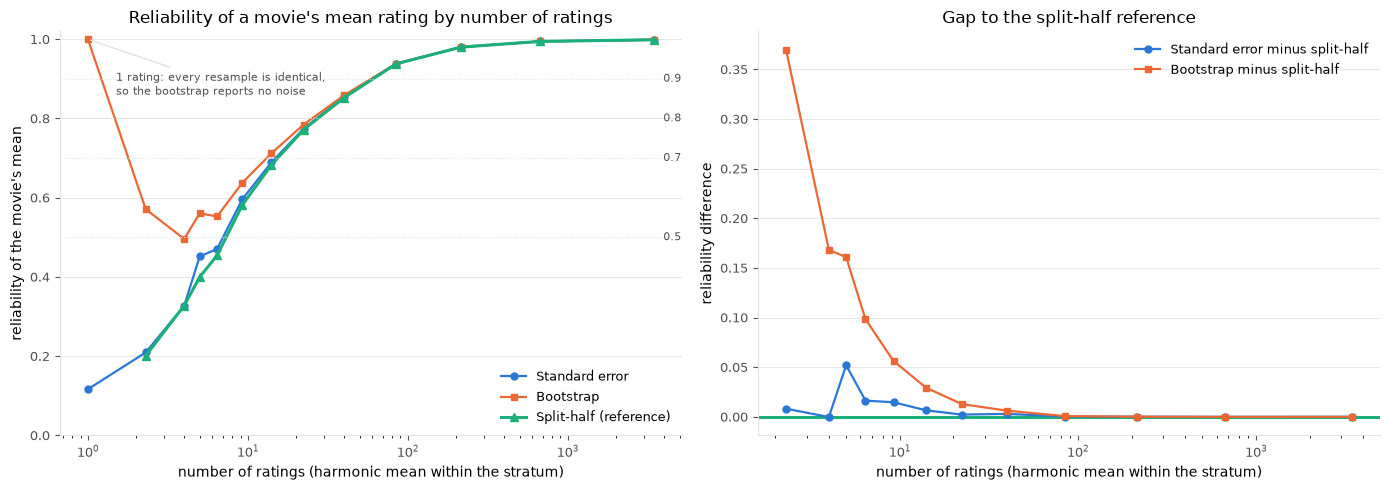

  n_harm  R_se  R_boot  R_split  se_gap  boot_gap
   2.299 0.209   0.571    0.201   0.008     0.370
   4.000 0.327   0.496    0.328  -0.000     0.168
   5.000 0.452   0.561    0.400   0.052     0.161
   6.421 0.471   0.553    0.454   0.016     0.098
   9.223 0.596   0.637    0.581   0.015     0.056
  14.051 0.689   0.712    0.683   0.007     0.029
  22.299 0.774   0.785    0.772   0.002     0.013
  39.979 0.855   0.859    0.852   0.003     0.006
  84.625 0.938   0.939    0.938   0.000     0.001
 215.348 0.980   0.980    0.980   0.000     0.000
 672.291 0.995   0.995    0.995  -0.000    -0.000
3441.557 0.999   0.999    0.999   0.000    -0.000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(table["n_harm"], table["R_se"], color=BLUE, marker="o", markersize=5, linewidth=1.6, label="Standard error")
ax.plot(table["n_harm"], table["R_boot"], color=ORANGE, marker="s", markersize=5, linewidth=1.6, label="Bootstrap")
ax.plot(table["n_harm"], table["R_split"], color=AQUA, marker="^", markersize=6, linewidth=2.2, label="Split-half (reference)")
for level in LEVELS:
    ax.axhline(level, color=GRID, linewidth=0.8, linestyle=":")
    ax.text(table["n_harm"].max() * 1.15, level, f"{level}", va="center", fontsize=8, color=MUTED)
ax.set(xscale="log", xlabel="number of ratings (harmonic mean within the stratum)", ylabel="reliability of the movie's mean",
       title="Reliability of a movie's mean rating by number of ratings", ylim=(0, 1.02))
ax.annotate("1 rating: every resample is identical,\nso the bootstrap reports no noise", xy=(1, 1.0), xytext=(1.5, 0.86),
            fontsize=8, color=MUTED, arrowprops={"arrowstyle": "-", "color": GRID})
ax.legend(frameon=False, fontsize=9, loc="lower right")
style_axes(ax)

ax = axes[1]
valid = table["stratum"] > 0
ax.axhline(0, color=AQUA, linewidth=2.2)
ax.plot(table.loc[valid, "n_harm"], (table["R_se"] - table["R_split"])[valid], color=BLUE, marker="o", markersize=5, linewidth=1.6, label="Standard error minus split-half")
ax.plot(table.loc[valid, "n_harm"], (table["R_boot"] - table["R_split"])[valid], color=ORANGE, marker="s", markersize=5, linewidth=1.6, label="Bootstrap minus split-half")
ax.set(xscale="log", xlabel="number of ratings (harmonic mean within the stratum)", ylabel="reliability difference",
       title="Gap to the split-half reference")
ax.legend(frameon=False, fontsize=9, loc="upper right")
style_axes(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q41_reliability_curves.png", dpi=150, bbox_inches="tight")
plt.show()

gap = table.loc[valid, ["n_harm", "R_se", "R_boot", "R_split"]].assign(
    se_gap=lambda d: d["R_se"] - d["R_split"], boot_gap=lambda d: d["R_boot"] - d["R_split"])
print(gap.round(3).to_string(index=False))

**Result.** The standard-error curve (with its stratum-specific σ²) tracks split-half closely: within 0.016 from about 6 ratings up, at most 0.052 (at 5 ratings), and within 0.008 below that. The bootstrap only catches up from about 22 ratings (gap 0.013); below that it is too optimistic. **Split-half and the standard error agree, so the curve is not an artifact of one method.** The bootstrap should not be used below about 20 ratings.

## 7. How many ratings for each reliability level?

Read the number of ratings at which the split-half curve reaches each level (interpolated between strata on a log scale), and the share of the catalog that has at least that many.

As a cross-check, the curve is compared with R = n / (n + k), the form that corresponds to Bayesian shrinkage with k phantom ratings. It is fitted only where reliability is between 0.2 and 0.95, since that is the range that matters for a cutoff. This is only a description of the curve; it does not replace the empirical numbers.

In [8]:
from scipy.optimize import least_squares

all_idx = np.arange(len(n))
curve_all = cr.stratum_curve(all_idx, n, strata, half_means, MIN_MOVIES_PER_STRATUM)
n_star = {level: cr.n_at_level(curve_all, level) for level in LEVELS}
nstar_global = pd.DataFrame({"reliability": LEVELS,
                             "ratings_needed": [n_star[l] for l in LEVELS],
                             "share_of_catalog_with_at_least": [(n >= n_star[l]).mean() for l in LEVELS]})
print(nstar_global.round(3).to_string(index=False))

band = (curve_all[:, 1] > 0.2) & (curve_all[:, 1] < 0.95)
residual = lambda k: curve_all[band, 1] - curve_all[band, 0] / (curve_all[band, 0] + k[0])
k_fit = least_squares(residual, [5.0]).x[0]
print(f"\nR = n / (n + k) with k = {k_fit:.1f}; largest gap to the empirical curve: {np.abs(residual([k_fit])).max():.3f}")

 reliability  ratings_needed  share_of_catalog_with_at_least
         0.5           7.316                           0.477
         0.7          15.361                           0.367
         0.8          27.366                           0.305
         0.9          60.671                           0.235

R = n / (n + k) with k = 7.3; largest gap to the empirical curve: 0.038


**Result.** On the split-half curve:

| Reliability | Ratings needed | Share of the catalog with at least that many |
|---|---|---|
| 0.5 | 7.3 | 47.7% |
| 0.7 | 15.4 | 36.7% |
| 0.8 | 27.4 | 30.5% |
| 0.9 | 60.7 | 23.5% |

R = n / (n + k) with k = 7.3 describes the curve to within 0.038. A smooth curve of that form has no sharp elbow: each extra rating adds about 0.034 reliability at 7 ratings, 0.006 at 27 and 0.002 at 61. Where to draw the line is a choice, not something the curve announces. More than half the catalog (52.3%) has fewer than 7.3 ratings, where less than half of the spread in means is real. The k of 7.3 is also the shrinkage strength a Bayesian average would use (Q4.3).

## 8. Does the curve differ by genre?

Thresholds are genre-specific (decided), so check whether one credibility curve fits every genre. Groups are the same as in `03_eda.ipynb`: the 10 largest genres (counted on movies with 10+ ratings) plus `Other`. A movie with several genres is counted in each of its genres.

For each genre the number of ratings needed is estimated from its own split-half curve. To judge whether a genre differs from the all-movies curve, the movies are resampled 4,000 times; in each resample both the genre's and the all-movies number are recomputed, so the difference carries the uncertainty of both. A genre is flagged when the interval for the difference excludes 0, shown at 95% and also with a Bonferroni correction for the 11 groups. The practical size of a difference is the share of the genre's movies whose "enough ratings" status would change if the genre used its own number instead of the global one.

To see why genres differ: R = τ² / (τ² + σ²/n), so a genre needs more ratings when its movies truly differ little from each other (small τ²) or its ratings are noisy (large σ²). Both are estimated for each genre.

In [9]:
def genre_groups(genres, n, n_top=10, min_ratings=10, exclude=("(no genres listed)", "IMAX")):
    """Group name -> positions of its movies. Top genres by movie count (movies with min_ratings+), the rest in Other."""
    exploded = (pd.DataFrame({"pos": np.arange(len(genres)), "genre": genres.str.split("|").to_numpy()})
                .explode("genre").dropna(subset=["genre"]))
    exploded = exploded[~exploded["genre"].isin(exclude)]
    top = exploded[n[exploded["pos"].to_numpy()] >= min_ratings]["genre"].value_counts().head(n_top).index
    exploded["group"] = exploded["genre"].where(exploded["genre"].isin(top), "Other")
    exploded = exploded.drop_duplicates(["pos", "group"])         # a movie counts once per group
    return {g: d["pos"].to_numpy() for g, d in exploded.groupby("group")}


groups = genre_groups(catalog["genres"], n)
print({g: len(i) for g, i in groups.items()})

BOOT_GENRE_PATH = ARTIFACTS_DIR / f"q41_genre_nstar_bootstrap_{VERSION}.parquet"

if BOOT_GENRE_PATH.exists():
    print(f"{BOOT_GENRE_PATH} already exists, loading instead of recomputing.")
    boot_genre = pd.read_parquet(BOOT_GENRE_PATH)
else:
    start = time.time()
    rng = np.random.default_rng(RANDOM_SEED + 3)
    rows = []
    for b in range(N_BOOT_MOVIES):
        picks = rng.integers(0, len(n), len(n))                   # resample movies with replacement
        times_picked = np.bincount(picks, minlength=len(n))
        for name, members in {"All": all_idx, **groups}.items():
            idx = picks if name == "All" else np.repeat(members, times_picked[members])
            curve = cr.stratum_curve(idx, n, strata, half_means, MIN_MOVIES_PER_STRATUM, REPEATS_IN_BOOT)
            rows.append({"resample": b, "group": name, **{f"n_{l}": cr.n_at_level(curve, l) for l in LEVELS}})
    boot_genre = pd.DataFrame(rows)
    boot_genre.to_parquet(BOOT_GENRE_PATH, index=False)
    write_metadata(BOOT_GENRE_PATH, resamples=N_BOOT_MOVIES, repeats_per_resample=REPEATS_IN_BOOT, seed=RANDOM_SEED + 3,
                   runtime_seconds=round(time.time() - start, 1),
                   note="ratings needed to reach each reliability level, for All movies and each genre group, on resampled movie sets")
    print(f"saved {len(boot_genre):,} rows to {BOOT_GENRE_PATH}")

{'Action': 6440, 'Adventure': 3541, 'Comedy': 14947, 'Crime': 4976, 'Documentary': 4705, 'Drama': 24206, 'Horror': 5177, 'Other': 10861, 'Romance': 7179, 'Sci-Fi': 2881, 'Thriller': 7846}
../artifacts/q41_genre_nstar_bootstrap_v1.parquet already exists, loading instead of recomputing.


all movies: 27.4 ratings needed at reliability 0.8

      group  movies  n_at_0.5  n_at_0.7  n_at_0.8  n_at_0.9  diff_vs_all  ci95_lo  ci95_hi  ci_bonf_lo  ci_bonf_hi  flag_95  flag_bonferroni  status_changes_for_share  sigma2  tau2
     Sci-Fi    2881     7.772    13.552    21.609    61.134       -5.757   -9.539    3.593     -12.168      11.143    False            False                     0.022   0.955 0.246
     Action    6440     7.864    14.619    22.549    56.118       -4.817   -7.539    0.839      -8.514       2.900    False            False                     0.018   0.930 0.233
     Comedy   14947     7.429    15.935    24.690    56.209       -2.675   -5.465    0.449      -6.410       1.679    False            False                     0.010   0.962 0.227
  Adventure    3541     7.568    12.224    26.409    59.242       -0.957  -10.077    5.335     -15.225       9.662    False            False                     0.004   0.945 0.243
      Other   10861     8.033    15.977    

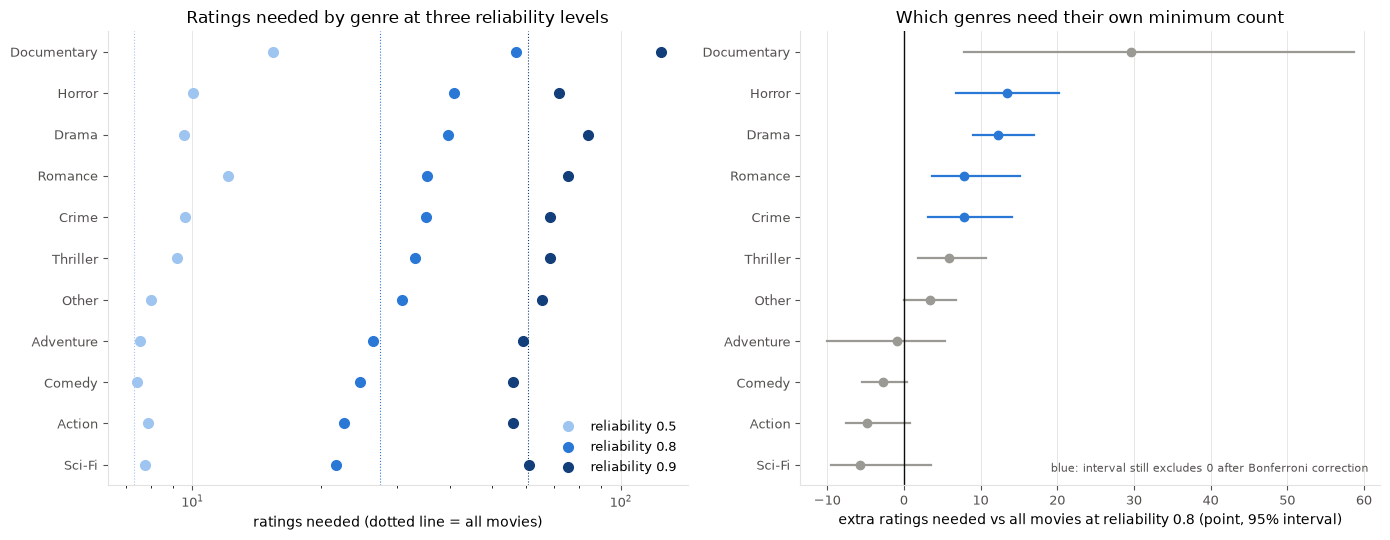

In [10]:
LEVEL = 0.8                                   # level used for the comparison; the ranking is checked at 0.5 and 0.9 too
alpha = 0.05 / len(groups)                    # Bonferroni correction for the number of genre groups
wide = boot_genre.pivot(index="resample", columns="group", values=f"n_{LEVEL}")
rows = []
for name, members in groups.items():
    curve = cr.stratum_curve(members, n, strata, half_means, MIN_MOVIES_PER_STRATUM)
    own = {l: cr.n_at_level(curve, l) for l in LEVELS}
    diff = (wide[name] - wide["All"]).dropna()
    lo95, hi95 = np.percentile(diff, [2.5, 97.5])
    loB, hiB = np.percentile(diff, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    low, high = sorted([own[LEVEL], n_star[LEVEL]])
    in_genre = n[members]
    # variance of true quality (tau^2) among movies that already have enough ratings, and within-movie noise (sigma^2)
    enough = in_genre >= n_star[LEVEL]
    sigma2 = pooled(in_genre[in_genre >= 2], var[members][in_genre >= 2])
    tau2 = mean[members][enough].var(ddof=1) - np.mean(var[members][enough] / in_genre[enough])
    rows.append({"group": name, "movies": len(members),
                 **{f"n_at_{l}": own[l] for l in LEVELS},
                 "diff_vs_all": own[LEVEL] - n_star[LEVEL], "ci95_lo": lo95, "ci95_hi": hi95,
                 "ci_bonf_lo": loB, "ci_bonf_hi": hiB,
                 "flag_95": (lo95 > 0) or (hi95 < 0), "flag_bonferroni": (loB > 0) or (hiB < 0),
                 "status_changes_for_share": ((in_genre >= low) & (in_genre < high)).mean(),
                 "sigma2": sigma2, "tau2": tau2})
genre_table = pd.DataFrame(rows).sort_values(f"n_at_{LEVEL}").reset_index(drop=True)
print(f"all movies: {n_star[LEVEL]:.1f} ratings needed at reliability {LEVEL}\n")
print(genre_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
y = np.arange(len(genre_table))
shades = {0.5: "#9ec5f0", 0.8: BLUE, 0.9: "#123e7a"}              # one hue, light to dark = low to high reliability
for level, shade in shades.items():
    ax.axvline(n_star[level], color=shade, linewidth=0.8, linestyle=":")
    ax.plot(genre_table[f"n_at_{level}"], y, "o", color=shade, markersize=7, label=f"reliability {level}")
ax.set_yticks(y, genre_table["group"], fontsize=9)
ax.set(xscale="log", xlabel="ratings needed (dotted line = all movies)", title="Ratings needed by genre at three reliability levels")
ax.legend(frameon=False, fontsize=9, loc="lower right")
style_axes(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.6)

ax = axes[1]
y = np.arange(len(genre_table))
for i, r in genre_table.iterrows():
    color = BLUE if r["flag_bonferroni"] else GRAY
    ax.plot([r["ci95_lo"], r["ci95_hi"]], [i, i], color=color, linewidth=1.6)
    ax.plot(r["diff_vs_all"], i, "o", color=color, markersize=6)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, genre_table["group"], fontsize=9)
ax.set(xlabel=f"extra ratings needed vs all movies at reliability {LEVEL} (point, 95% interval)",
       title="Which genres need their own minimum count")
ax.text(0.98, 0.03, "blue: interval still excludes 0 after Bonferroni correction", transform=ax.transAxes,
        ha="right", fontsize=8, color=MUTED)
style_axes(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID, linewidth=0.6)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q41_genre_reliability.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** Ratings needed at reliability 0.8 (all movies: 27.4):

| Genre group | Ratings needed | Difference vs all (95% interval) | Flagged | Movies whose status would change |
|---|---|---|---|---|
| Documentary | 57.0 | +29.7 (7.8 to 58.7) | 95% only | 5.9% |
| Horror | 40.8 | +13.5 (6.8 to 20.3) | yes | 3.9% |
| Drama | 39.6 | +12.2 (9.0 to 17.0) | yes | 3.6% |
| Romance | 35.2 | +7.9 (3.7 to 15.2) | yes | 2.5% |
| Crime | 35.2 | +7.8 (3.2 to 14.1) | yes | 2.6% |
| Thriller | 33.2 | +5.8 (1.9 to 10.8) | 95% only | 2.2% |
| Other | 30.8 | +3.5 (−0.0 to 6.8) | no | 1.1% |
| Adventure | 26.4 | −1.0 (−10.1 to 5.3) | no | 0.4% |
| Comedy | 24.7 | −2.7 (−5.5 to 0.4) | no | 1.0% |
| Action | 22.5 | −4.8 (−7.5 to 0.8) | no | 1.8% |
| Sci-Fi | 21.6 | −5.8 (−9.5 to 3.6) | no | 2.2% |

"Flagged" means the interval for the difference excludes 0 after the Bonferroni correction for 11 groups (yes) or only at 95% ("95% only").

- Four genres clearly need more ratings than the all-movies number: Horror, Drama, Romance and Crime. Documentary needs the most (about twice the all-movies number), but it is a smaller genre and its interval is wide, so it is flagged only at 95%. Thriller is borderline.
- The size of the effect is small in practice. Even for Documentary, only 5.9% of its movies would change status (between "enough ratings" and "not enough") if it used its own number instead of the global one. For the other genres it is 0.4% to 3.9%, because most movies are far below or far above the cutoff.
- Documentary is highest at all three reliability levels (15.4, 57.0 and 124.3 ratings at 0.5, 0.8 and 0.9). The rest of the order shifts a little between levels.
- Why: genres with a narrow spread of true quality need more ratings. The between-movie variance (τ²) is 0.113 for Documentary and 0.140 for Drama, against 0.23–0.25 for Action, Adventure and Sci-Fi. The within-movie noise (σ²) is similar across genres (0.82 to 1.02); Horror has the highest at 1.02.

## 9. Save the results

The three small result tables go to `artifacts/` as CSV with one metadata file. The expensive intermediates (histogram, bootstrap, split-half means, genre resamples) were saved when they were computed.

In [11]:
table_out = table.drop(columns=["mean_inv_n"]).rename(columns={"R_se": "reliability_standard_error",
                                                                "R_boot": "reliability_bootstrap",
                                                                "R_split": "reliability_split_half"})
table_out.to_csv(ARTIFACTS_DIR / f"q41_reliability_by_stratum_{VERSION}.csv", index=False)
nstar_global.to_csv(ARTIFACTS_DIR / f"q41_nstar_global_{VERSION}.csv", index=False)
genre_table.to_csv(ARTIFACTS_DIR / f"q41_nstar_by_genre_{VERSION}.csv", index=False)
write_metadata(ARTIFACTS_DIR / "q41_results.csv", version=VERSION, seed=RANDOM_SEED, strata=N_STRATA, repeats=N_REPEATS,
               n_boot=N_BOOT, n_boot_movies=N_BOOT_MOVIES, levels=LEVELS, comparison_level=LEVEL,
               population="50,046 rated movies in movies_full.parquet",
               files=[f"q41_reliability_by_stratum_{VERSION}.csv", f"q41_nstar_global_{VERSION}.csv", f"q41_nstar_by_genre_{VERSION}.csv"],
               key_metrics={f"ratings_needed_at_{l}": round(n_star[l], 1) for l in LEVELS})
print("saved result tables to", ARTIFACTS_DIR)

saved result tables to ../artifacts


## Summary and decision (Q4.1)

**Question.** How many ratings until a movie's mean rating is trustworthy?

**Findings**
- Reliability of a movie's mean is a smooth, saturating curve of the number of ratings. It has no sharp elbow, so any cutoff is a choice of level.
- Three methods agree (standard error with stratum-specific variance, split-half as the reference; the bootstrap only above about 20 ratings).
- Half of the observed spread in means is real at 7.3 ratings, 70% at 15.4, 80% at 27.4 and 90% at 60.7. These are reached by 47.7%, 36.7%, 30.5% and 23.5% of the catalog.
- Genres differ. Horror, Drama, Romance and Crime need more ratings than the all-movies number (Documentary and Thriller too at 95%), but for any genre at most 5.9% of its movies would change status if it used its own number.

**Limitations**
- This measures sampling noise, not bias. People who watch obscure movies are not a random sample, so a movie with 200 ratings can still be consistently over- or under-rated.
- The raters are MovieLens users, not all viewers.
- The 16.4% of movies with a single rating cannot be split or bootstrapped; their reliability (0.12) assumes the same σ² as movies with 2–3 ratings.
- Reliability is estimated per rating-count stratum, and the spread of true quality differs between strata, so it describes the movies at that count.
- The genre comparison counts a multi-genre movie in each of its genres (as decided). The intervals come from resampling movies and so do not treat those copies as independent, but the groups overlap, so the 11 comparisons are not independent either. The Bonferroni correction is conservative for that reason.
- Genre groups follow `03_eda.ipynb` (10 largest genres plus Other); the 7 IMDb-only genres sit inside Other.
- Only the 24,744,432 ratings of the 50,046 catalog movies are used (255,663 ratings of filtered-out title types are excluded).

**Decision (2026-10-08).** Reliability 0.8, about 28 ratings, one global count. It is used as flags (`enough_r50/70/80/90`), not as a filter. Genre-specific counts were not adopted: they change status for at most 5.9% of a genre's movies.

## Enough-ratings flags on the cleaned catalog

Q4.1 decided that a movie's mean is trustworthy at reliability 0.8 (about 27 ratings). That level is a convention, so instead of one fixed cutoff this adds one True/False column per level to the cleaned catalog (`approved_movies.parquet`, from `03_eda.ipynb`). **Nothing is dropped**: the columns only mark which movies pass, so the cost of each level can be seen before it is used.

The minimum counts come from `artifacts/q41_nstar_global_v1.csv`, not typed in, and are rounded up (27.4 needed means 28). The output is a new file; `approved_movies.parquet` is not changed. Percentages here are of the 33,802 approved movies, so they differ from the Q4.1 percentages, which are of all 50,046 rated movies.

In [12]:
FLAGS_PATH = PROCESSED_DIR / f"approved_movies_credibility_{VERSION}.parquet"

if FLAGS_PATH.exists():
    print(f"{FLAGS_PATH} already exists, loading instead of recomputing.")
    approved = pd.read_parquet(FLAGS_PATH)
else:
    approved = pd.read_parquet(PROCESSED_DIR / "approved_movies.parquet")
    nstar_table = pd.read_csv(ARTIFACTS_DIR / f"q41_nstar_global_{VERSION}.csv")
    approved, minimums = cr.add_enough_ratings_flags(approved, nstar_table)
    approved.to_parquet(FLAGS_PATH, index=False)
    write_metadata(FLAGS_PATH, source=["data/processed/approved_movies.parquet", f"artifacts/q41_nstar_global_{VERSION}.csv"],
                   minimum_ratings=minimums, rows=len(approved),
                   passing={c: int(approved[c].sum()) for c in minimums},
                   note="True/False column per reliability level; nothing dropped; minimum count is ratings_needed rounded up")
    print(f"saved {len(approved):,} rows to {FLAGS_PATH}")

flag_cols = [c for c in approved.columns if c.startswith("enough_r")]
print(pd.DataFrame({"min_ratings": [approved.loc[approved[c], "rating_count"].min() for c in flag_cols],
                    "movies_passing": [approved[c].sum() for c in flag_cols],
                    "share_of_approved": [approved[c].mean() for c in flag_cols]}, index=flag_cols).round(3).to_string())

../data/processed/approved_movies_credibility_v1.parquet already exists, loading instead of recomputing.
            min_ratings  movies_passing  share_of_approved
enough_r50            8           21800              0.645
enough_r70           16           17433              0.516
enough_r80           28           14774              0.437
enough_r90           61           11656              0.345


## Q4.3: early and late ratings

Q4.3 asks which score to use for a movie: the raw mean, or a mean shrunk toward the overall average. The test is a time split: build the score from a movie's early ratings, then check how well it predicts the mean of its later ratings.

No cutoff date is picked by hand. The rating timeline is not uniform (2015 to 2018 hold about a quarter of all ratings), so the test is run at four cutoffs, the 50th, 70th, 80th and 90th percentiles of all rating timestamps, to see whether the winner depends on the date. For each movie and cutoff this stores the number of ratings before the cutoff and their sum; the late ratings are the movie's total minus the early ones. One pass over `ratings.csv`, saved to `artifacts/`.

In [13]:
EARLY_QUANTILES = [0.5, 0.7, 0.8, 0.9]
EARLY_PATH = ARTIFACTS_DIR / f"q43_early_counts_{VERSION}.parquet"

if EARLY_PATH.exists():
    print(f"{EARLY_PATH} already exists, loading instead of recomputing.")
    early = pd.read_parquet(EARLY_PATH)
else:
    start = time.time()
    early = cr.build_early_counts(RATINGS_CSV, hist["movieId"], EARLY_QUANTILES)
    early.to_parquet(EARLY_PATH, index=False)
    write_metadata(EARLY_PATH, source="data/raw/movielens/ml-25m/ratings.csv", quantiles=EARLY_QUANTILES,
                   cutoffs={str(q): pd.to_datetime(t, unit="s").isoformat() for q, t in
                            early.groupby("quantile")["cutoff_ts"].first().items()},
                   movies=int(early["movieId"].nunique()), runtime_seconds=round(time.time() - start, 1),
                   note="per movie and cutoff: ratings before the cutoff (count and sum); late = total minus early")
    print(f"saved {len(early):,} rows to {EARLY_PATH}")

# early counts can never exceed the totals, and sums must be consistent with the histogram
total = pd.DataFrame({"movieId": hist["movieId"], "n_total": n, "sum_total": n * mean})
chk = early.merge(total, on="movieId")
assert (chk["n_early"] <= chk["n_total"]).all() and (chk["sum_early"] <= chk["sum_total"] + 1e-6).all()
print(early.groupby("quantile").agg(cutoff=("cutoff_ts", lambda s: pd.to_datetime(s.iloc[0], unit="s").date()),
                                    movies_with_early=("n_early", lambda s: (s > 0).sum())).to_string())

../artifacts/q43_early_counts_v1.parquet already exists, loading instead of recomputing.
              cutoff  movies_with_early
quantile                               
0.5       2007-12-28               9539
0.7       2015-01-22              21442
0.8       2016-06-25              30852
0.9       2018-01-04              38957


## Q4.3: raw mean vs shrunk mean, tested on later ratings

**Problem.** A movie's early mean is a noisy guess of how it will be rated later, especially with few ratings. The score will be used as a priority weight, so it should predict well and rank well.

**Candidates** (all built from a movie's early ratings only):
1. **Raw mean**: the baseline.
2. **Shrunk mean, k = 7.3**: pulled toward the prior as if the movie had k extra ratings at the prior value. k comes from the Q4.1 reliability curve (R = n / (n + k)), not tuned here.
3. **Shrunk mean, tuned k**: the k that minimises error on a random half of the test movies; it is scored on the other half.
4. **Hard weight**: the raw mean if the movie has at least 28 early ratings (the 0.8 level), otherwise the prior.

**Prior.** The mean of the per-movie early means over all movies that have early ratings at that cutoff, so it uses nothing from after the cutoff.

**Test.** Approved movies with at least one early rating and at least L late ratings, so the late mean is itself credible. L is 28 (the main run) and also 8 and 61 as a sensitivity check. Error is squared error against the late mean; rank quality is Spearman correlation with the late mean. Results are split by number of early ratings, using the Q4.1 levels (8, 16, 28, 61) as band edges. The gap between each method and the raw mean gets a paired bootstrap interval.

In [14]:
MINIMUMS = [8, 16, 28, 61]                      # Q4.1 minimum ratings for reliability 0.5 / 0.7 / 0.8 / 0.9
BANDS = [1] + MINIMUMS + [np.inf]
BAND_LABELS = ["1-7", "8-15", "16-27", "28-60", "61+"]
LATE_MINIMUMS = [28, 8, 61]                     # main run first, then the sensitivity runs
N_BOOT_SCORE = 1000
CMP_PATH = ARTIFACTS_DIR / f"q43_score_comparison_{VERSION}.csv"

if CMP_PATH.exists():
    print(f"{CMP_PATH} already exists, loading instead of recomputing.")
    cmp = pd.read_csv(CMP_PATH)
else:
    from scipy.stats import spearmanr
    start = time.time()
    approved_ids = set(approved["movieId"])
    totals = pd.DataFrame({"movieId": hist["movieId"], "n_total": n, "sum_total": n * mean})
    data = early.merge(totals, on="movieId")
    rng = np.random.default_rng(RANDOM_SEED + 4)
    rows = []
    for late_min in LATE_MINIMUMS:
        for q, d in data.groupby("quantile"):
            d = d.assign(n_late=d["n_total"] - d["n_early"],
                         mean_early=d["sum_early"] / d["n_early"],
                         mean_late=(d["sum_total"] - d["sum_early"]) / (d["n_total"] - d["n_early"]))
            prior = d.loc[d["n_early"] > 0, "mean_early"].mean()
            ev = d[d["movieId"].isin(approved_ids) & (d["n_early"] >= 1) & (d["n_late"] >= late_min)]
            half = rng.random(len(ev)) < 0.5
            fit, test = ev[half], ev[~half]
            k_tuned = cr.best_k(fit["n_early"], fit["mean_early"], fit["mean_late"], prior)
            scores = {"raw": test["mean_early"].to_numpy(),
                      "shrunk_k_from_Q4.1": cr.shrunk_mean(test["n_early"], test["mean_early"], prior, k_fit),
                      "shrunk_k_tuned": cr.shrunk_mean(test["n_early"], test["mean_early"], prior, k_tuned),
                      "hard_weight_28": cr.hard_weight_mean(test["n_early"], test["mean_early"], prior, 28)}
            y = test["mean_late"].to_numpy()
            band = pd.cut(test["n_early"], BANDS, right=False, labels=BAND_LABELS).to_numpy()
            picks = rng.integers(0, len(y), (N_BOOT_SCORE, len(y)))
            raw_err = (scores["raw"] - y) ** 2
            for name, v in scores.items():
                err = (v - y) ** 2
                diff = (err - raw_err)[picks].mean(axis=1)                  # paired: same resampled movies
                row = {"late_min": late_min, "cutoff_quantile": q, "method": name,
                       "k": {"shrunk_k_from_Q4.1": k_fit, "shrunk_k_tuned": k_tuned}.get(name, np.nan),
                       "prior": prior, "test_movies": len(y), "mse": err.mean(), "spearman": spearmanr(v, y)[0],
                       "mse_minus_raw": err.mean() - raw_err.mean(),
                       "diff_ci_lo": np.percentile(diff, 2.5), "diff_ci_hi": np.percentile(diff, 97.5)}
                for lb in BAND_LABELS:
                    m = band == lb
                    row[f"mse_{lb}"] = err[m].mean() if m.any() else np.nan
                    row[f"n_{lb}"] = int(m.sum())
                rows.append(row)
    cmp = pd.DataFrame(rows)
    cmp.to_csv(CMP_PATH, index=False)
    write_metadata(CMP_PATH, seed=RANDOM_SEED + 4, k_from_Q4_1=float(k_fit), late_minimums=LATE_MINIMUMS,
                   cutoff_quantiles=EARLY_QUANTILES, n_boot=N_BOOT_SCORE, band_edges=MINIMUMS,
                   runtime_seconds=round(time.time() - start, 1),
                   note="raw vs shrunk vs hard-weight scores, scored against the later mean; approved movies only")

main = cmp[cmp["late_min"] == 28]
print(main[["cutoff_quantile", "method", "k", "test_movies", "mse", "mse_minus_raw", "diff_ci_lo", "diff_ci_hi", "spearman"]]
      .round(3).to_string(index=False))

../artifacts/q43_score_comparison_v1.csv already exists, loading instead of recomputing.
 cutoff_quantile             method      k  test_movies   mse  mse_minus_raw  diff_ci_lo  diff_ci_hi  spearman
             0.5                raw    NaN         3460 0.050          0.000       0.000       0.000     0.907
             0.5 shrunk_k_from_Q4.1  7.324         3460 0.045         -0.005      -0.007      -0.004     0.907
             0.5     shrunk_k_tuned 32.789         3460 0.042         -0.008      -0.010      -0.006     0.899
             0.5     hard_weight_28    NaN         3460 0.052          0.002      -0.000       0.004     0.897
             0.7                raw    NaN         4313 0.063          0.000       0.000       0.000     0.870
             0.7 shrunk_k_from_Q4.1  7.324         4313 0.047         -0.016      -0.021      -0.011     0.875
             0.7     shrunk_k_tuned  7.686         4313 0.047         -0.016      -0.021      -0.011     0.875
             0.7     ha

## Q4.4: rating floor — keep the rule from `04_eda.ipynb`

The floor already exists: a movie's rating is too low when it is below μ − 1σ of its genre (most forgiving genre for multi-genre movies), combined with the per-genre count levels and the time test into the approve rule. It is kept, and rebuilt as a function (`src/viberec/tiers.py`) so it can be rerun with other settings. It reproduces 04's 33,812 approved movies exactly.

**Choice (Adil):**
- **"Too low" stays on the raw mean**, exactly as in 04. A low average on few ratings is still rejected, and borderline movies that 04 approved stay approved.
- **"Too high" uses the shrunk score from Q4.3.** A too-good-to-be-true average from a handful of ratings is pulled back to normal, so those movies are no longer rejected. This is the `hybrid` rule below.

Two things about it were never tested, and the next two sections test them:
1. The hand-set multipliers `LOWER_SD = 1` and `UPPER_SD = 2` (sensitivity, Q4.6).
2. Whether the rule removes movies that really are worse (validation, Q4.7). The raw-mean rule, the all-shrunk rule and the hybrid are compared.

Q4.5 (new-movie range) is deferred: MovieLens ends in 2019, with 17 rated movies from 2020 on, so there is nothing to learn it from.

In [15]:
from src.viberec import tiers

rule_movies = rated[["movieId", "genres", "year", "rating_count", "mean_rating"]].copy()
PRIOR_FULL = rule_movies["mean_rating"].mean()                     # global per-movie mean (Q4.3 decision)
rule_movies["shrunk"] = cr.shrunk_mean(rule_movies["rating_count"], rule_movies["mean_rating"], PRIOR_FULL, k_fit)

check = tiers.approve_rule(rule_movies)
assert check["approve"].sum() == 33_812                           # same as 04_eda before its 10 no-genre rows were dropped
print(f"prior {PRIOR_FULL:.3f}, k {k_fit:.2f}; 04 rule reproduced: {check['approve'].sum():,} approved")

prior 3.073, k 7.32; 04 rule reproduced: 33,812 approved


## Q4.6: sensitivity — do the hand-set multipliers matter?

Rerun the rule with `LOWER_SD` from 0.5 to 1.5 and `UPPER_SD` from 1.5 to 3 (or no upper limit), on the raw mean and on the shrunk score. For each setting: the share of rated movies rejected, and how many movies flip between approved and rejected compared with the 1 / 2 setting. If few flip, the hand-set value is harmless; if many flip, the value needs evidence (from Q4.7).

In [16]:
SENS_PATH = ARTIFACTS_DIR / f"q46_sensitivity_{VERSION}.csv"
LOWER_GRID = [0.5, 0.75, 1.0, 1.25, 1.5]
UPPER_GRID = [1.5, 2.0, 2.5, 3.0, None]

if SENS_PATH.exists():
    print(f"{SENS_PATH} already exists, loading instead of recomputing.")
    sens = pd.read_csv(SENS_PATH)
else:
    start = time.time()
    rows = []
    for score in ["mean_rating", "shrunk"]:
        baseline = set(tiers.approve_rule(rule_movies, score_col=score).query("approve")["movieId"])
        for lo in LOWER_GRID:
            for up in UPPER_GRID:
                kept = set(tiers.approve_rule(rule_movies, score_col=score, lower_sd=lo, upper_sd=up).query("approve")["movieId"])
                rows.append({"score": score, "lower_sd": lo, "upper_sd": "none" if up is None else up,
                             "approved": len(kept), "rejected_pct": 100 * (1 - len(kept) / len(rule_movies)),
                             "flips_vs_1_2": len(kept ^ baseline)})
    sens = pd.DataFrame(rows)
    sens.to_csv(SENS_PATH, index=False)
    write_metadata(SENS_PATH, lower_grid=LOWER_GRID, upper_grid=[str(u) for u in UPPER_GRID], k=float(k_fit),
                   prior=float(PRIOR_FULL), population="50,046 rated movies", runtime_seconds=round(time.time() - start, 1))

for score in ["mean_rating", "shrunk"]:
    s = sens[sens["score"] == score]
    print(f"\n{score}: % of rated movies rejected")
    print(s.pivot(index="lower_sd", columns="upper_sd", values="rejected_pct").round(1).to_string())
    print(f"{score}: movies that flip vs LOWER_SD = 1, UPPER_SD = 2")
    print(s.pivot(index="lower_sd", columns="upper_sd", values="flips_vs_1_2").to_string())

../artifacts/q46_sensitivity_v1.csv already exists, loading instead of recomputing.

mean_rating: % of rated movies rejected
upper_sd   1.5   2.0   2.5   3.0  none
lower_sd                              
0.50      41.6  40.4  39.6  39.3  39.2
0.75      37.8  36.6  35.9  35.6  35.5
1.00      33.6  32.4  31.7  31.4  31.3
1.25      31.2  30.1  29.3  29.0  28.9
1.50      28.4  27.2  26.5  26.2  26.1
mean_rating: movies that flip vs LOWER_SD = 1, UPPER_SD = 2
upper_sd   1.5   2.0   2.5   3.0  none
lower_sd                              
0.50      4568  3969  4343  4491  4560
0.75      2701  2102  2476  2624  2693
1.00       599     0   374   522   591
1.25      1793  1194  1568  1716  1785
1.50      3205  2606  2980  3128  3197

shrunk: % of rated movies rejected
upper_sd   1.5   2.0   2.5   3.0  none
lower_sd                              
0.50      36.4  36.4  36.4  36.4  36.4
0.75      29.1  29.1  29.1  29.1  29.1
1.00      24.0  24.0  24.0  24.0  24.0
1.25      21.3  21.3  21.3  21.3  21.3

**Result.**
- **`UPPER_SD` barely matters.** On the raw mean it moves at most 599 movies (1.2 points of rejection); on the shrunk score at most 1. It existed to catch 5.0 averages from one or two ratings, and shrinkage already pulls those back, so on the shrunk score it does nothing.
- **`LOWER_SD` matters.** Each 0.25 step moves 1,200 to 2,700 movies on the raw mean (rejection from 26% to 42% across the grid), and 1,400 to 6,200 on the shrunk score (19% to 36%). It has no flat region, so its value has to be justified by outcomes (Q4.7), not by stability.
- **Raw vs shrunk.** At 1 / 2 the shrunk score rejects 24.0% of rated movies against 32.4% for the raw mean: 4,220 movies are rejected on the raw mean only, 13 on the shrunk score only.

## Q4.7: validation — does the rule remove movies that really are worse?

Use the early/late split from Q4.3. At each cutoff the rule is run on the **early** ratings only (counts, means, genre ranges, and the time test with the cutoff year as "now"). Then the movies' **later** ratings decide whether it was right. Movies count only with at least L later ratings (L = 8 and 28).

Two measures:
- **Approved vs rejected.** AUC = the chance that a random approved movie ends up with a higher later mean than a random rejected one (0.5 = the rule is no better than chance). Checked for every `LOWER_SD` in the grid and for both scores.
- **Three tiers** (PROJECT.md §4.2), Kruskal-Wallis on the later mean:
  - Tier 1, excluded: rejected with a too-low rating. Old, not high-count, low-rated, so it matches the three conditions of §4.1.
  - Tier 2, reduced weight: rejected for any other reason, mostly few ratings with a normal or high rating (the movies §4.1 says should survive).
  - Tier 3: approved.

  If the tiers' later ratings do not differ, the tiers are meaningless.

In [17]:
from scipy.stats import kruskal, mannwhitneyu

VAL_PATH = ARTIFACTS_DIR / "q47_validation_v2.csv"            # v2: adds the "hybrid" rule
TIER_VAL_PATH = ARTIFACTS_DIR / "q47_tier_validation_v2.csv"
# which score decides "too low" and which decides "too high"
RULES = {"mean_rating": {"score_col": "mean_rating"},
         "shrunk": {"score_col": "shrunk"},
         "hybrid": {"score_col": "mean_rating", "upper_score_col": "shrunk"}}   # too low on the raw mean, too high on the shrunk score

if VAL_PATH.exists() and TIER_VAL_PATH.exists():
    print("validation results already exist, loading instead of recomputing.")
    val, tier_val = pd.read_csv(VAL_PATH), pd.read_csv(TIER_VAL_PATH)
else:
    start = time.time()
    info = rated[["movieId", "genres", "year"]].assign(n_total=rated["rating_count"], sum_total=rated["rating_count"] * rated["mean_rating"])
    rows, tier_rows = [], []
    for q, d in early.merge(info, on="movieId").groupby("quantile"):
        cutoff_year = pd.to_datetime(d["cutoff_ts"].iloc[0], unit="s").year
        d = d[d["n_early"] > 0].assign(rating_count=lambda x: x["n_early"], mean_rating=lambda x: x["sum_early"] / x["n_early"],
                                       n_late=lambda x: x["n_total"] - x["n_early"],
                                       mean_late=lambda x: (x["sum_total"] - x["sum_early"]) / (x["n_total"] - x["n_early"]))
        d["shrunk"] = cr.shrunk_mean(d["n_early"], d["mean_rating"], d["mean_rating"].mean(), k_fit)
        for score, rule in RULES.items():
            for lo in LOWER_GRID:
                out = tiers.approve_rule(d, **rule, lower_sd=lo, data_year=cutoff_year).merge(d[["movieId", "n_late", "mean_late"]], on="movieId")
                out["tier"] = tiers.assign_tier(out)
                for late_min in (8, 28):
                    v = out[out["n_late"] >= late_min]
                    a, r = v.loc[v["approve"], "mean_late"], v.loc[~v["approve"], "mean_late"]
                    u = mannwhitneyu(a, r).statistic if len(r) else np.nan
                    rows.append({"cutoff_quantile": q, "cutoff_year": cutoff_year, "score": score, "lower_sd": lo, "late_min": late_min,
                                 "rejected_share": 1 - out["approve"].mean(), "approved": len(a), "rejected": len(r),
                                 "median_late_approved": a.median(), "median_late_rejected": r.median(), "auc": u / (len(a) * len(r)) if len(r) else np.nan})
                    if lo != 1.0:
                        continue
                    groups = [v.loc[v["tier"] == t, "mean_late"] for t in (1, 2, 3)]
                    testable = all(len(g) >= 5 for g in groups)
                    h, p = kruskal(*groups) if testable else (np.nan, np.nan)
                    tier_rows.append({"cutoff_quantile": q, "cutoff_year": cutoff_year, "score": score, "late_min": late_min,
                                      **{f"n_tier{t}": len(g) for t, g in zip((1, 2, 3), groups)},
                                      **{f"median_tier{t}": g.median() for t, g in zip((1, 2, 3), groups)},
                                      "kruskal_h": h, "kruskal_p": p, "epsilon2": h / (len(v) - 1) if testable else np.nan,
                                      "p_tier1_vs_2": mannwhitneyu(groups[0], groups[1]).pvalue if testable else np.nan,
                                      "p_tier2_vs_3": mannwhitneyu(groups[1], groups[2]).pvalue if testable else np.nan})
    val, tier_val = pd.DataFrame(rows), pd.DataFrame(tier_rows)
    val.to_csv(VAL_PATH, index=False)
    tier_val.to_csv(TIER_VAL_PATH, index=False)
    for path in (VAL_PATH, TIER_VAL_PATH):
        write_metadata(path, cutoff_quantiles=EARLY_QUANTILES, lower_grid=LOWER_GRID, late_minimums=[8, 28], k=float(k_fit),
                       runtime_seconds=round(time.time() - start, 1),
                       note="rule run on early ratings only; later mean is the outcome; tiers at LOWER_SD = 1, UPPER_SD = 2; rules: mean_rating, shrunk, hybrid")

for late_min in (28, 8):
    print(f"\nAUC approved vs rejected, at least {late_min} later ratings (columns = cutoff year)")
    print(val[val["late_min"] == late_min].pivot_table(index=["score", "lower_sd"], columns="cutoff_year", values="auc").round(3).to_string())
print("\nTiers at LOWER_SD = 1 (median later mean per tier, Kruskal-Wallis)")
print(tier_val[["cutoff_year", "score", "late_min", "n_tier1", "n_tier2", "n_tier3", "median_tier1", "median_tier2", "median_tier3",
                "kruskal_p", "epsilon2", "p_tier1_vs_2", "p_tier2_vs_3"]].round(3).to_string(index=False))

validation results already exist, loading instead of recomputing.

AUC approved vs rejected, at least 28 later ratings (columns = cutoff year)
cutoff_year            2007   2015   2016   2018
score       lower_sd                            
hybrid      0.50      0.739  0.833  0.839  0.940
            0.75      0.720  0.843  0.858  0.954
            1.00      0.696  0.838  0.878  0.978
            1.25      0.662  0.827  0.878  0.979
            1.50      0.626  0.808  0.881  0.994
mean_rating 0.50      0.739  0.827  0.826  0.940
            0.75      0.720  0.835  0.840  0.954
            1.00      0.696  0.827  0.854  0.978
            1.25      0.662  0.812  0.847  0.979
            1.50      0.626  0.790  0.837  0.994
shrunk      0.50      0.742  0.837  0.850  0.940
            0.75      0.722  0.849  0.876  0.954
            1.00      0.703  0.846  0.884  0.978
            1.25      0.669  0.831  0.885  0.978
            1.50      0.642  0.814  0.883  0.994

AUC approved vs rejecte

**Result.**
- **The rule works.** At every cutoff, approved movies get clearly higher later ratings than rejected ones: AUC 0.70 to 0.98 (L = 28) and 0.71 to 0.87 (L = 8) at `LOWER_SD = 1`. Median later mean is 3.33 to 3.43 for approved movies against 2.06 to 2.97 for rejected ones.
- **The shrunk score does at least as well as the raw mean while rejecting fewer movies.** Its AUC is equal or higher in 37 of 40 comparisons (the 3 exceptions are lower by 0.001). On the full data it rejects 24.0% against 32.4%.
- **The chosen hybrid rule** judges "too low" on the raw mean and "too high" on the shrunk score. It is equal to or better than the raw-mean rule in all 40 comparisons, for example 0.854 → 0.878 at the 2016 cutoff. It sits a little below the all-shrunk rule (at most 0.008 lower at L = 28). That is the cost of rejecting low averages on few ratings, which was Adil's choice. Its tiers differ just as clearly (below).
- **`LOWER_SD = 1` stays.** The best value moves with the cutoff (0.5 at 2007, 0.75 at 2015, 1.25 at 2016, 1.5 at 2018 for L = 28), so no other value is consistently better. 1 is within 0.04 AUC of the best at every cutoff.
- **The three tiers differ**, for all three rules. Kruskal-Wallis p < 0.001 at every cutoff with enough movies in each tier (ε² 0.02 to 0.14, small to medium; it shrinks at later cutoffs because tiers 1 and 2 get small).
  - Tier 1's later mean is about 2.5, against about 3.1 to 3.4 for tier 2 and 3.3 to 3.4 for tier 3, and tier 1 vs 2 is significant everywhere. Excluding tier 1 is justified.
  - Tier 2 sits between the others. With at least 8 later ratings it is a little below tier 3 (3.11 to 3.22 against 3.33), significant at most cutoffs. With at least 28, it is indistinguishable from tier 3 (p 0.57 to 0.81). These are the low-count but normally rated movies that 04 rejected. They turn out about as good as approved movies, so they get reduced weight, not exclusion. That is what PROJECT.md §4.1 asked for.

**Limitations.**
- Only movies that kept being rated have later ratings, so the test favours movies that stayed popular. That matters most for tier 2: with at least 28 later ratings it holds only 4 to 421 movies.
- At the 2018 cutoff there is no tier-2 movie with 28+ later ratings. At the 2016 cutoff there are 4 to 5, so those rows are not testable.
- The later mean is MovieLens's average, a proxy for quality and not any one user's taste. Genres are not adjusted for (the rule is genre-relative, the outcome is not).

## Final tiers

The rule runs on the full data with the **hybrid** rule (too low on the raw mean, too high on the shrunk score), `LOWER_SD = 1` and `UPPER_SD = 2`. Every rated movie gets a tier, so **nothing is deleted**:
- Tier 1 is the excluded set.
- Tier 2's weight is not hand-set. PROJECT.md §4.3 item 9 says the ranker learns it (Step 10).
- The `enough_r*` flags from Q4.1 and the shrunk score are included.

It is saved as a new file (v2; v1 used the all-shrunk rule), and `approved_movies.parquet` is left as it is.

Compared with 04's approve rule: the 591 movies 04 rejected as "too high on few ratings" are now approved, and nothing else moves into or out of the approved set.

In [18]:
TIERS_PATH = PROCESSED_DIR / "movie_tiers_v2.parquet"           # v2: hybrid rule (v1 used the shrunk score for both sides)

if TIERS_PATH.exists():
    print(f"{TIERS_PATH} already exists, loading instead of recomputing.")
    movie_tiers = pd.read_parquet(TIERS_PATH)
else:
    final = tiers.approve_rule(rule_movies, score_col="mean_rating", upper_score_col="shrunk", lower_sd=1.0, upper_sd=2.0)
    final["tier"] = tiers.assign_tier(final)
    movie_tiers = (rated[["movieId", "tconst", "tmdbId", "title", "genres", "year", "rating_count", "mean_rating"]]
                   .merge(rule_movies[["movieId", "shrunk"]].rename(columns={"shrunk": "shrunk_score"}), on="movieId")
                   .merge(final[["movieId", "tier", "reason"]], on="movieId"))
    movie_tiers, _ = cr.add_enough_ratings_flags(movie_tiers, pd.read_csv(ARTIFACTS_DIR / f"q41_nstar_global_{VERSION}.csv"))
    movie_tiers.to_parquet(TIERS_PATH, index=False)
    write_metadata(TIERS_PATH, source="data/processed/movies_full.parquet", rule="hybrid: too low on the raw mean, too high on the shrunk mean", k=float(k_fit), prior=float(PRIOR_FULL),
                   lower_sd=1.0, upper_sd=2.0, margin_years=8, rows=len(movie_tiers),
                   tier_counts={int(t): int(c) for t, c in movie_tiers["tier"].value_counts().items()},
                   note="tier 1 = excluded, 2 = reduced weight (learned by the ranker later), 3 = approved; nothing deleted")
    print(f"saved {len(movie_tiers):,} rows to {TIERS_PATH}")

print(movie_tiers["tier"].value_counts().sort_index().to_frame("movies").assign(share=lambda d: (d["movies"] / d["movies"].sum()).round(3)))
print(pd.crosstab(movie_tiers["reason"], movie_tiers["tier"]))
in_04 = movie_tiers["movieId"].isin(pd.read_parquet(PROCESSED_DIR / "approved_movies.parquet")["movieId"])
print(f"\n04's 33,802 approved movies by new tier: {movie_tiers.loc[in_04, 'tier'].value_counts().sort_index().to_dict()}")

# the approved movies (tier 3)
approved_v2 = movie_tiers[movie_tiers["tier"] == 3]
print(f"\napproved (tier 3): {approved_v2.shape[0]:,} rows, {approved_v2.shape[1]} columns")
approved_v2.head(10)

../data/processed/movie_tiers_v2.parquet already exists, loading instead of recomputing.
      movies  share
tier               
1      10452  0.209
2       5191  0.104
3      34403  0.687
tier            1     2      3
reason                        
approved        0     0  34403
low_count    3289  5191      0
mid_too_low  7163     0      0

04's 33,802 approved movies by new tier: {3: 33802}

approved (tier 3): 34,403 rows, 15 columns


,movieId,tconst,tmdbId,title,genres,year,rating_count,mean_rating,shrunk_score,tier,reason,enough_r50,enough_r70,enough_r80,enough_r90
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,57309.0,3.893708,3.893603,3,approved,True,True,True,True
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,24228.0,3.251527,3.251473,3,approved,True,True,True,True
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,11804.0,3.142028,3.141985,3,approved,True,True,True,True
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,2523.0,2.853547,2.854183,3,approved,True,True,True,True
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,11714.0,3.058434,3.058444,3,approved,True,True,True,True
5,6,tt0113277,949.0,Heat (1995),Action|Crime|Thriller,1995.0,24588.0,3.854909,3.854676,3,approved,True,True,True,True
6,7,tt0114319,11860.0,Sabrina (1995),Comedy|Romance,1995.0,12132.0,3.363666,3.363491,3,approved,True,True,True,True
7,8,tt0112302,45325.0,Tom and Huck (1995),Adventure|Children,1995.0,1344.0,3.114583,3.114359,3,approved,True,True,True,True
8,9,tt0114576,9091.0,Sudden Death (1995),Action,1995.0,3711.0,2.992051,2.992210,3,approved,True,True,True,True
9,10,tt0113189,710.0,GoldenEye (1995),Action|Adventure|Thriller,1995.0,28265.0,3.421458,3.421367,3,approved,True,True,True,True


## Step 4 summary

| | Decision | Evidence |
|---|---|---|
| Q4.1 | A mean is trustworthy from about 28 ratings (reliability 0.8). Kept as flags. | Split-half reliability curve |
| Q4.3 | Score = shrunk mean, k = 7.3, prior = global per-movie mean | Beats the raw mean on later ratings in 12 of 12 settings |
| Q4.4 | Floor = 04's μ − 1σ per-genre rule. "Too low" judged on the raw mean (Adil's choice), "too high" on the shrunk score | Hybrid rule's AUC is equal or better than 04's raw rule in all 40 comparisons |
| Q4.6 | `LOWER_SD = 1` matters, `UPPER_SD = 2` does not | Sensitivity grid |
| Q4.7 | Tiers: 1 excluded (10,452, 20.9%), 2 reduced weight (5,191, 10.4%), 3 approved (34,403, 68.7%) | Later ratings differ across tiers (Kruskal-Wallis p < 0.001); tier 2 ≈ tier 3 with 28+ later ratings |

**Output:** `data/processed/movie_tiers_v2.parquet`, which has all 50,046 rated movies with `shrunk_score`, `tier`, `reason` and the `enough_r*` flags.

**From 04 to now:**
- 04 approved 33,812. Now 34,403 are approved: 33,812 plus the 591 movies rejected only for a too-good-to-be-true average on few ratings.
- 04's other 15,643 rejected movies are kept in the file, not deleted:
  - 10,452 in tier 1 (a too-low raw average);
  - 5,191 in tier 2 (few ratings but a normal or high average).

**Not done here:**
- Q4.2 (age buckets) and Q4.5 (new-movie range) wait for newer data.
- `MARGIN_YEARS = 8` cannot be tested on this data.
- Tier 2's weight is learned by the ranker in Step 10.